In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=d5e70e58-c1b1-42f3-bdc8-8f848ff9d5ee
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:09<00:00, 82.2MB/s] 

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noisy_metadata_v2.csv
    noise_manifest_v2.json
    b6000_split.csv
    clean_500/
        V/
            00002472_V_500_roll_04.png
            00002650_V_500_roll_03.png
            00002481_V_500_roll_07.png
            00002578_V_500_roll_04.png
            00002394_V_500_roll_04.png
            00002375_V_500_roll_08.png
            00002544_V_500_roll_04.png
            00002313_V_500_roll_03.png
            00002604_V_500_roll_08.png
            00002518_V_500_roll_03.png
            00002488_V_500_roll_03.png
            00002424_V_500_roll_02.png
            00002489_V_500_roll_08.png
            00002354_V_500_roll_01.png
            00002611_V_500_roll_01.png
            00002556_V_500_roll_08.png
            00002348_V_500_roll_10.png
            00002644_V_500_roll_03.png
            00002534_V_500_roll_08.png
            00002483_V_500_roll_09.png
        S/
            00002575_S_500_slap_03.png
            00002446_S_500_slap_06

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
clean_list.csv
noisy_metadata_v2.csv
noise_manifest_v2.json
b6000_split.csv
noisy_500_v2/V/00002472_V_500_roll_04.png
noisy_500_v2/V/00002650_V_500_roll_03.png
noisy_500_v2/V/00002481_V_500_roll_07.png
noisy_500_v2/V/00002578_V_500_roll_04.png
noisy_500_v2/V/00002394_V_500_roll_04.png
noisy_500_v2/V/00002375_V_500_roll_08.png
noisy_500_v2/V/00002544_V_500_roll_04.png
noisy_500_v2/V/00002313_V_500_roll_03.png
noisy_500_v2/V/00002604_V_500_roll_08.png
noisy_500_v2/V/00002518_V_500_roll_03.png
noisy_500_v2/V/00002488_V_500_roll_03.png
noisy_500_v2/V/00002424_V_500_roll_02.png
noisy_500_v2/V/00002489_V_500_roll_08.png
noisy_500_v2/V/00002354_V_500_roll_01.png
noisy_500_v2/V/00002611_V_500_roll_01.png
noisy_500_v2/V/00002556_V_500_roll_08.png
noisy_500_v2/V/00002348_V_500_roll_10.png
noisy_500_v2/V/00002644_V_500_roll_03.png
noisy_500_v2/V/00002534_V_500_roll_08.png
noisy_500_v2/V/00002483_V_

In [6]:
import os, time, random, math
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from skimage.metrics import peak_signal_noise_ratio as sk_psnr, structural_similarity as sk_ssim
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path("/kaggle/working/dataset/noise_project_v2")
IMG = 256
CKPT = Path("/kaggle/working/pgan_ckpt"); CKPT.mkdir(exist_ok=True)
print(DEV)

cuda


In [7]:
df = pd.read_csv(ROOT / "b6000_split.csv")
print(df.shape)
print(df.head())
for c in df.columns:
    if df[c].nunique() < 10:
        print(c, df[c].value_counts().to_dict())

(6000, 30)
  source                     key  participant device  ppi         capture  \
0      b  00002302_R_500_slap_01         2302      R  500  slap-segmented   
1      b  00002302_R_500_slap_02         2302      R  500  slap-segmented   
2      b  00002302_R_500_slap_03         2302      R  500  slap-segmented   
3      b  00002302_R_500_slap_04         2302      R  500  slap-segmented   
4      b  00002302_R_500_slap_05         2302      R  500  slap-segmented   

   frgp finger_name                                         zip_member  \
0     1     R thumb  sd302b/images/baseline/R/500/slap-segmented/pn...   
1     2     R index  sd302b/images/baseline/R/500/slap-segmented/pn...   
2     3    R middle  sd302b/images/baseline/R/500/slap-segmented/pn...   
3     4      R ring  sd302b/images/baseline/R/500/slap-segmented/pn...   
4     5    R little  sd302b/images/baseline/R/500/slap-segmented/pn...   

                                              sha256  ...  items_9_325  \
0  c5ee

In [9]:
df["_fname"] = df["key"].astype(str) + ".png"
df["_dev"]   = df["device"].astype(str)
df["_clean"] = df.apply(lambda r: str(ROOT/"clean_500"/r["_dev"]/r["_fname"]), axis=1)
df["_noisy"] = df.apply(lambda r: str(ROOT/"noisy_500_v2"/r["_dev"]/r["_fname"]), axis=1)

exists = df["_clean"].map(os.path.exists) & df["_noisy"].map(os.path.exists)
print("rows in csv:", len(df), "| pairs present in folder:", int(exists.sum()))

df = df[exists].copy()
df["_split"] = df["split"].astype(str).str.lower()
print(df["_split"].value_counts())

rows in csv: 6000 | pairs present in folder: 2490
_split
train    1764
val       388
test      338
Name: count, dtype: int64


In [15]:
CROP = 256

def pad_to(img, s):
    h, w = img.shape
    ph, pw = max(0, s-h), max(0, s-w)
    return cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_REFLECT) if (ph or pw) else img

def center_crop(img, s):
    img = pad_to(img, s); h, w = img.shape
    y, x = (h-s)//2, (w-s)//2
    return img[y:y+s, x:x+s]

def read_pair(r):
    n = cv2.imread(r["_noisy"], 0); c = cv2.imread(r["_clean"], 0)
    assert n.shape == c.shape, r["_fname"]
    return n, c

d_tr = df[df["_split"] == "train"].reset_index(drop=True)
d_va = df[df["_split"] == "val"].reset_index(drop=True)
d_te = df[df["_split"] == "test"].reset_index(drop=True)

tr = [read_pair(r) for _, r in tqdm(d_tr.iterrows(), total=len(d_tr), desc="train")]
va = [read_pair(r) for _, r in tqdm(d_va.iterrows(), total=len(d_va), desc="val")]

tr_n_list, tr_c_list = [p[0] for p in tr], [p[1] for p in tr]
va_n = np.stack([center_crop(p[0], CROP) for p in va])   # val: fixed center crops
va_c = np.stack([center_crop(p[1], CROP) for p in va])

data = {"train": (d_tr, tr_n_list, tr_c_list), "val": (d_va, va_n, va_c), "test": (d_te, None, None)}
print("sample image shape:", tr_n_list[0].shape, "| train/val/test:", len(d_tr), len(d_va), len(d_te))

train:   0%|          | 0/1764 [00:00<?, ?it/s]

val:   0%|          | 0/388 [00:00<?, ?it/s]

sample image shape: (574, 352) | train/val/test: 1764 388 338


In [16]:
CH = {4:256, 8:256, 16:256, 32:128, 64:64, 128:32, 256:32}

def cb(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, 1, 1), nn.InstanceNorm2d(o, affine=True), nn.LeakyReLU(0.2, True),
        nn.Conv2d(o, o, 3, 1, 1), nn.InstanceNorm2d(o, affine=True), nn.LeakyReLU(0.2, True))

class Gen(nn.Module):
    def __init__(s):
        super().__init__()
        res = [256, 128, 64, 32, 16]
        enc_r = [256, 128, 64, 32, 16, 8]
        s.frm  = nn.ModuleDict({str(r): nn.Conv2d(1, CH[r], 1) for r in res})
        s.toimg = nn.ModuleDict({str(r): nn.Conv2d(CH[r], 1, 1) for r in res})
        s.enc  = nn.ModuleDict({str(r): cb(CH[r], CH[r]) for r in enc_r})
        s.down = nn.ModuleDict({str(r): nn.Sequential(nn.Conv2d(CH[r], CH[r//2], 4, 2, 1), nn.LeakyReLU(0.2, True)) for r in enc_r})
        s.bott = cb(CH[4], CH[4])
        s.up   = nn.ModuleDict({str(r): nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(CH[r//2], CH[r], 3, 1, 1), nn.LeakyReLU(0.2, True)) for r in enc_r[::-1]})
        s.dec  = nn.ModuleDict({str(r): cb(2*CH[r], CH[r]) for r in enc_r[::-1]})

    def forward(s, x, R, alpha=1.0):
        fade = alpha < 1.0 and R > 32
        h = s.frm[str(R)](x)
        if fade: low = s.frm[str(R//2)](F.avg_pool2d(x, 2))
        skips, r = {}, R
        while r >= 8:
            sk = s.enc[str(r)](h); skips[r] = sk
            h = s.down[str(r)](sk)
            if fade and r == R: h = alpha*h + (1-alpha)*low
            r //= 2
        h = s.bott(h)
        prev, r = None, 8
        while r <= R:
            prev = h
            h = s.up[str(r)](h)
            h = s.dec[str(r)](torch.cat([h, skips[r]], 1))
            r *= 2
        out = s.toimg[str(R)](h)
        if fade:
            lo = F.interpolate(s.toimg[str(R//2)](prev), scale_factor=2, mode="nearest")
            out = alpha*out + (1-alpha)*lo
        return torch.tanh(out)

class Disc(nn.Module):   # PatchGAN, input = concat(noisy, clean/fake) = 2 channels
    def __init__(s):
        super().__init__()
        res = [256, 128, 64, 32, 16]
        s.frm = nn.ModuleDict({str(r): nn.Sequential(nn.Conv2d(2, CH[r], 1), nn.LeakyReLU(0.2, True)) for r in res})
        s.blk = nn.ModuleDict({str(r): nn.Sequential(
            nn.Conv2d(CH[r], CH[r], 3, 1, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(CH[r], CH[r//2], 4, 2, 1), nn.LeakyReLU(0.2, True)) for r in [256,128,64,32,16,8]})
        s.out = nn.Conv2d(CH[4], 1, 3, 1, 1)

    def forward(s, x, R, alpha=1.0):
        fade = alpha < 1.0 and R > 32
        h = s.frm[str(R)](x)
        if fade: low = s.frm[str(R//2)](F.avg_pool2d(x, 2))
        r = R
        while r >= 8:
            h = s.blk[str(r)](h)
            if fade and r == R: h = alpha*h + (1-alpha)*low
            r //= 2
        return s.out(h)

G, D = Gen().to(DEV), Disc().to(DEV)
print("G params (M):", sum(p.numel() for p in G.parameters())/1e6)
x = torch.randn(2, 1, 256, 256, device=DEV)
print(G(x, 256, 0.5).shape, D(torch.cat([x, x], 1), 256, 0.5).shape)

G params (M): 12.483301
torch.Size([2, 1, 256, 256]) torch.Size([2, 1, 4, 4])


In [17]:
def to_t(a): return torch.from_numpy(a).float().div(127.5).sub(1).unsqueeze(1)

def rand_crop(n, c):
    n, c = pad_to(n, CROP), pad_to(c, CROP)
    h, w = n.shape
    y, x = random.randint(0, h-CROP), random.randint(0, w-CROP)
    n, c = n[y:y+CROP, x:x+CROP], c[y:y+CROP, x:x+CROP]
    if random.random() < 0.5: n, c = n[:, ::-1], c[:, ::-1]
    k = random.randint(0, 3)
    return np.rot90(n, k), np.rot90(c, k)

def batches(noisy, clean, bs, shuffle=True, aug=True):
    idx = np.random.permutation(len(noisy)) if shuffle else np.arange(len(noisy))
    for i in range(0, len(idx), bs):
        pairs = [rand_crop(noisy[j], clean[j]) for j in idx[i:i+bs]]
        n = np.stack([p[0] for p in pairs]); c = np.stack([p[1] for p in pairs])
        yield to_t(n).to(DEV), to_t(c).to(DEV)


def down_to(x, R): return x if R == IMG else F.interpolate(x, size=(R, R), mode="area")

def calc_metrics(a, b):   # a: prediction/noisy, b: clean (uint8)
    psnr = sk_psnr(b, a, data_range=255)
    ssim = sk_ssim(b, a, data_range=255)
    rmse = float(np.sqrt(np.mean((a.astype(np.float64) - b.astype(np.float64))**2)))
    return psnr, ssim, rmse

@torch.no_grad()
def enhance(G, noisy_u8, bs=16):
    G.eval(); outs = []
    for i in range(0, len(noisy_u8), bs):
        y = G(to_t(noisy_u8[i:i+bs]).to(DEV), IMG, 1.0)
        outs.append(((y.clamp(-1, 1) + 1) * 127.5).round().byte().squeeze(1).cpu().numpy())
    return np.concatenate(outs)

def eval_set(G, noisy, clean):
    enh = enhance(G, noisy)
    m = np.array([calc_metrics(enh[i], clean[i]) for i in range(len(enh))])
    return m.mean(0)   # psnr, ssim, rmse

In [18]:
G, D = Gen().to(DEV), Disc().to(DEV)
oG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.9, 0.999))
oD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.9, 0.999))
bce, l1 = nn.BCEWithLogitsLoss(), nn.L1Loss()

LAM = 100
BS = 8
STAGES = [32, 64, 128, 256]
EP_PER_STAGE = 4
FADE_EP = 2           
FINETUNE_EP = 60      
VAL_EVERY = 5

tr_n, tr_c = data["train"][1], data["train"][2]
va_n, va_c = data["val"][1], data["val"][2]
nb = math.ceil(len(tr_n) / BS)

def step(n, c, R, alpha):
    n, c = down_to(n, R), down_to(c, R)
    fake = G(n, R, alpha)
    d_real = D(torch.cat([n, c], 1), R, alpha)
    d_fake = D(torch.cat([n, fake.detach()], 1), R, alpha)
    lD = 0.5 * (bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake)))
    oD.zero_grad(set_to_none=True); lD.backward(); oD.step()

    d_fake = D(torch.cat([n, fake], 1), R, alpha)
    adv, rec = bce(d_fake, torch.ones_like(d_fake)), l1(fake, c)
    lG = adv + LAM * rec
    oG.zero_grad(set_to_none=True); lG.backward(); oG.step()
    return lD.item(), adv.item(), rec.item()

# Phase 1: progressive growing
for si, R in enumerate(STAGES):
    it = 0
    for ep in range(EP_PER_STAGE):
        G.train(); D.train(); logs = []
        for n, c in tqdm(batches(tr_n, tr_c, BS, aug=True), total=nb, desc=f"R={R} ep{ep+1}", leave=False):
            alpha = 1.0 if si == 0 else min(1.0, it / (FADE_EP * nb))
            logs.append(step(n, c, R, alpha)); it += 1
        print(f"[R={R}] ep{ep+1} alpha={alpha:.2f} D={np.mean([l[0] for l in logs]):.3f} "
              f"Gadv={np.mean([l[1] for l in logs]):.3f} L1={np.mean([l[2] for l in logs]):.4f}")
    torch.save({"G": G.state_dict(), "D": D.state_dict()}, CKPT / f"stage_{R}.pt")

# Phase 2: fine-tune at 256, best val SSIM save
best_ssim = -1
for ep in range(FINETUNE_EP):
    G.train(); D.train(); logs = []
    for n, c in batches(tr_n, tr_c, BS, aug=True):
        logs.append(step(n, c, 256, 1.0))
    msg = f"[FT] ep{ep+1}/{FINETUNE_EP} D={np.mean([l[0] for l in logs]):.3f} L1={np.mean([l[2] for l in logs]):.4f}"
    if (ep + 1) % VAL_EVERY == 0:
        p, s_, r = eval_set(G, va_n, va_c)
        msg += f" | VAL PSNR={p:.2f} SSIM={s_:.4f} RMSE={r:.2f}"
        if s_ > best_ssim:
            best_ssim = s_
            torch.save(G.state_dict(), CKPT / "best_G.pt"); msg += "  <- best"
    print(msg)
print("best val SSIM:", best_ssim)

R=32 ep1:   0%|          | 0/221 [00:00<?, ?it/s]

[R=32] ep1 alpha=1.00 D=0.559 Gadv=1.081 L1=0.2674


R=32 ep2:   0%|          | 0/221 [00:00<?, ?it/s]

[R=32] ep2 alpha=1.00 D=0.599 Gadv=0.958 L1=0.2127


R=32 ep3:   0%|          | 0/221 [00:00<?, ?it/s]

[R=32] ep3 alpha=1.00 D=0.678 Gadv=0.735 L1=0.1965


... (22 outputs left out)

R=256 ep3:   0%|          | 0/221 [00:00<?, ?it/s]

[R=256] ep3 alpha=1.00 D=0.425 Gadv=1.530 L1=0.2582


R=256 ep4:   0%|          | 0/221 [00:00<?, ?it/s]

[R=256] ep4 alpha=1.00 D=0.399 Gadv=1.640 L1=0.2377
[FT] ep1/60 D=0.448 L1=0.2259
[FT] ep2/60 D=0.515 L1=0.2179
[FT] ep3/60 D=0.500 L1=0.2107
[FT] ep4/60 D=0.532 L1=0.2113
[FT] ep5/60 D=0.525 L1=0.2069 | VAL PSNR=14.77 SSIM=0.7840 RMSE=48.70  <- best
[FT] ep6/60 D=0.542 L1=0.1989
[FT] ep7/60 D=0.527 L1=0.1967
[FT] ep8/60 D=0.558 L1=0.1926
[FT] ep9/60 D=0.551 L1=0.1896
[FT] ep10/60 D=0.548 L1=0.1895 | VAL PSNR=15.64 SSIM=0.8153 RMSE=44.14  <- best
[FT] ep11/60 D=0.567 L1=0.1844
[FT] ep12/60 D=0.562 L1=0.1818
[FT] ep13/60 D=0.576 L1=0.1835
[FT] ep14/60 D=0.615 L1=0.1762
[FT] ep15/60 D=0.599 L1=0.1747 | VAL PSNR=15.89 SSIM=0.8206 RMSE=42.97  <- best
[FT] ep16/60 D=0.565 L1=0.1722
[FT] ep17/60 D=0.575 L1=0.1746
[FT] ep18/60 D=0.590 L1=0.1729
[FT] ep19/60 D=0.580 L1=0.1710
[FT] ep20/60 D=0.582 L1=0.1703 | VAL PSNR=16.16 SSIM=0.8323 RMSE=41.48  <- best
[FT] ep21/60 D=0.573 L1=0.1682
[FT] ep22/60 D=0.587 L1=0.1655
[FT] ep23/60 D=0.584 L1=0.1677
[FT] ep24/60 D=0.588 L1=0.1627
[FT] ep25/60 D=0.

In [19]:
!pip install -q "nbis-python>=0.1.17"
import nbis
from nbis import NbisExtractorSettings

def make_ext(ppi):
    s = NbisExtractorSettings(min_quality=0.0, get_center=False, check_fingerprint=False,
                              compute_nfiq2=True, ppi=ppi)
    return nbis.new_nbis_extractor(s)
try:    ext = make_ext(500)
except Exception as ex:
    print("ppi=500 not accepted, using default:", ex); ext = make_ext(None)

def nfiq2_score(img):
    ok, buf = cv2.imencode(".png", img)
    try:    return float(ext.extract_minutiae(buf.tobytes()).quality().score)
    except Exception: return np.nan

print("sanity (clean):", [nfiq2_score(cv2.imread(p, 0)) for p in d_te["_clean"][:5]])

sanity (clean): [74.0, 65.0, 66.0, 66.0, 73.0]


In [20]:
G.load_state_dict(torch.load(CKPT / "best_G.pt")); G.eval()

@torch.no_grad()
def enhance_full(img):                       # full image, 64 ke multiple tak reflect pad
    h, w = img.shape
    x = np.pad(img, ((0, (-h) % 64), (0, (-w) % 64)), mode="reflect")
    y = G(to_t(x[None]).to(DEV), IMG, 1.0)
    return ((y[0, 0, :h, :w].clamp(-1, 1) + 1) * 127.5).round().byte().cpu().numpy()

out_dir = Path("/kaggle/working/pgan_test_out")
for d in "UVSR": (out_dir / d).mkdir(parents=True, exist_ok=True)
_ = enhance_full(cv2.imread(d_te["_noisy"][0], 0))      # warm-up

rows, times = [], []
for _, r in tqdm(d_te.iterrows(), total=len(d_te), desc="test"):
    n, c = read_pair(r)
    torch.cuda.synchronize(); t0 = time.time()
    e = enhance_full(n)
    torch.cuda.synchronize(); times.append(time.time() - t0)
    cv2.imwrite(str(out_dir / r["_dev"] / r["_fname"]), e)
    pn, sn, rn = calc_metrics(n, c); pe, se, re_ = calc_metrics(e, c)
    rows.append(dict(fname=r["_fname"], device=r["_dev"], noisy=r["_noisy"], clean=r["_clean"],
                     noisy_psnr=pn, enh_psnr=pe, noisy_ssim=sn, enh_ssim=se,
                     noisy_rmse=rn, enh_rmse=re_,
                     noisy_nfiq2=nfiq2_score(n), enh_nfiq2=nfiq2_score(e), clean_nfiq2=nfiq2_score(c)))

res = pd.DataFrame(rows)
res.to_csv("/kaggle/working/pgan_test_metrics.csv", index=False)

def summ(d):
    t = pd.DataFrame({
        "Before (noisy)":   [d.noisy_ssim.mean(), d.noisy_psnr.mean(), d.noisy_rmse.mean(), d.noisy_nfiq2.mean()],
        "After (enhanced)": [d.enh_ssim.mean(),   d.enh_psnr.mean(),   d.enh_rmse.mean(),   d.enh_nfiq2.mean()]},
        index=["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"])
    t["Change"] = t["After (enhanced)"] - t["Before (noisy)"]
    return t.round(3)

print(f"Test images: {len(res)} | Avg enhancement time: {np.mean(times):.3f} s/image")
display(summ(res))
print("Clean reference NFIQ2 mean:", round(res.clean_nfiq2.mean(), 2))
v = res.dropna(subset=["noisy_nfiq2", "enh_nfiq2"])
print(f"NFIQ2 improved on {(v.enh_nfiq2 > v.noisy_nfiq2).sum()} of {len(v)} images")
print(f"SSIM improved on {(res.enh_ssim > res.noisy_ssim).sum()} of {len(res)} images")
print("NaN counts:", res[["noisy_nfiq2", "enh_nfiq2", "clean_nfiq2"]].isna().sum().to_dict())
for d in "UVSR":
    print(f"\nDevice {d} (n={(res.device == d).sum()})"); display(summ(res[res.device == d]))

test:   0%|          | 0/338 [00:00<?, ?it/s]

Test images: 338 | Avg enhancement time: 0.079 s/image


,Before (noisy),After (enhanced),Change
SSIM,0.672,0.891,0.219
PSNR (dB),13.288,18.729,5.442
RMSE,57.600,30.657,-26.943
NFIQ2,20.083,69.219,49.136


Clean reference NFIQ2 mean: 71.77
NFIQ2 improved on 337 of 338 images
SSIM improved on 338 of 338 images
NaN counts: {'noisy_nfiq2': 0, 'enh_nfiq2': 0, 'clean_nfiq2': 0}

Device U (n=104)


,Before (noisy),After (enhanced),Change
SSIM,0.766,0.920,0.153
PSNR (dB),14.728,19.801,5.073
RMSE,48.003,26.919,-21.084
NFIQ2,18.885,63.010,44.125



Device V (n=81)


,Before (noisy),After (enhanced),Change
SSIM,0.732,0.919,0.187
PSNR (dB),14.652,19.798,5.146
RMSE,48.489,26.877,-21.611
NFIQ2,24.198,67.494,43.296



Device S (n=93)


,Before (noisy),After (enhanced),Change
SSIM,0.586,0.862,0.275
PSNR (dB),11.906,17.805,5.899
RMSE,66.689,33.766,-32.924
NFIQ2,20.247,74.645,54.398



Device R (n=60)


,Before (noisy),After (enhanced),Change
SSIM,0.558,0.849,0.291
PSNR (dB),11.091,16.861,5.771
RMSE,72.445,37.418,-35.027
NFIQ2,16.350,73.900,57.550


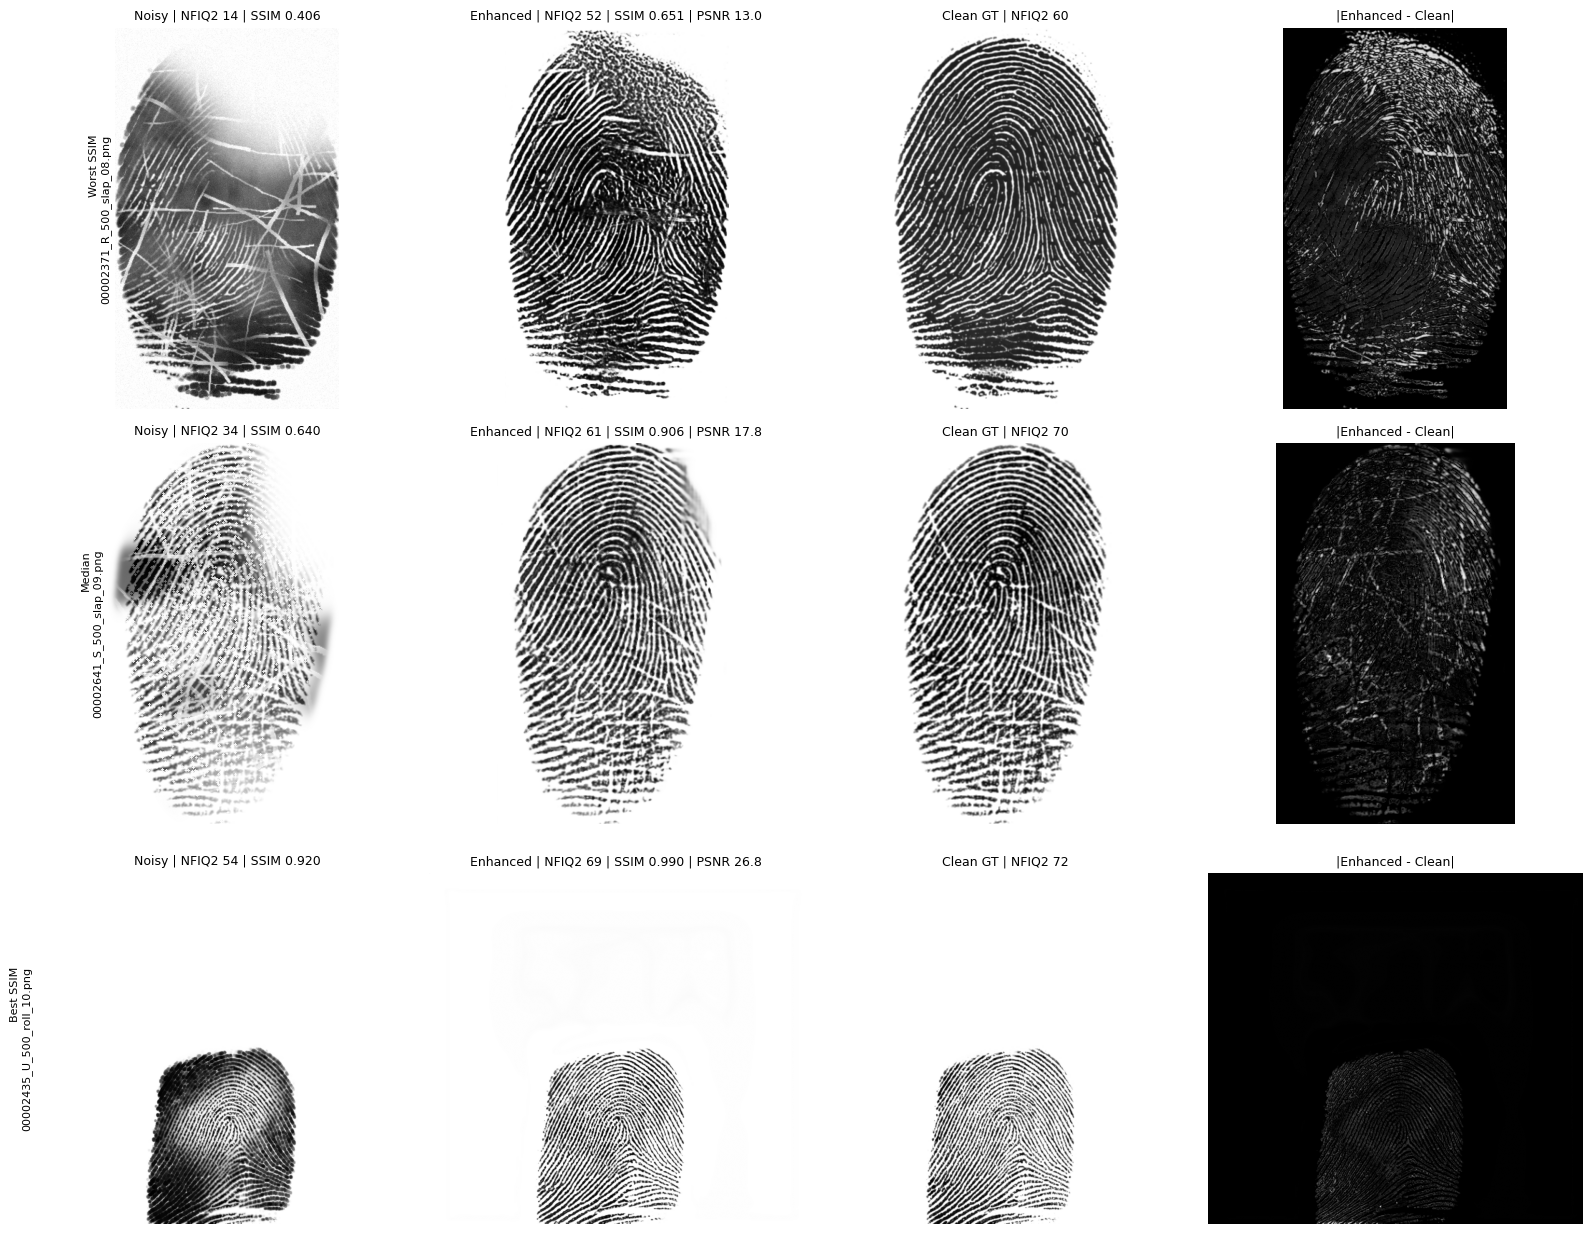

In [21]:
sel = res.sort_values("enh_ssim")
picks = [("Worst SSIM", sel.iloc[0]), ("Median", sel.iloc[len(sel)//2]), ("Best SSIM", sel.iloc[-1])]
fig, axs = plt.subplots(len(picks), 4, figsize=(16, 4.2*len(picks)))
for i, (tag, r) in enumerate(picks):
    n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
    e = cv2.imread(str(out_dir / r.device / r.fname), 0)
    diff = np.abs(e.astype(int) - c.astype(int)).astype(np.uint8)
    items = [(n, f"Noisy | NFIQ2 {r.noisy_nfiq2:.0f} | SSIM {r.noisy_ssim:.3f}"),
             (e, f"Enhanced | NFIQ2 {r.enh_nfiq2:.0f} | SSIM {r.enh_ssim:.3f} | PSNR {r.enh_psnr:.1f}"),
             (c, f"Clean GT | NFIQ2 {r.clean_nfiq2:.0f}"),
             (diff, "|Enhanced - Clean|")]
    for j, (im, t) in enumerate(items):
        axs[i, j].imshow(im, cmap="gray", vmin=0, vmax=255); axs[i, j].set_title(t, fontsize=9); axs[i, j].axis("off")
    axs[i, 0].text(-0.02, 0.5, f"{tag}\n{r.fname}", transform=axs[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.savefig("/kaggle/working/pgan_visuals.png", dpi=130); plt.show()

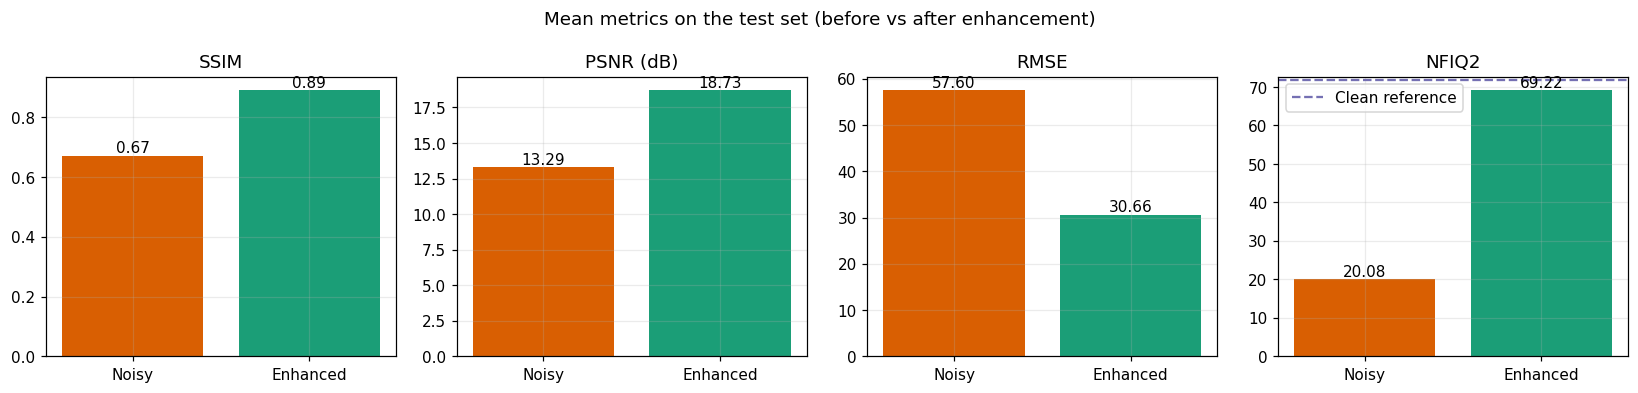

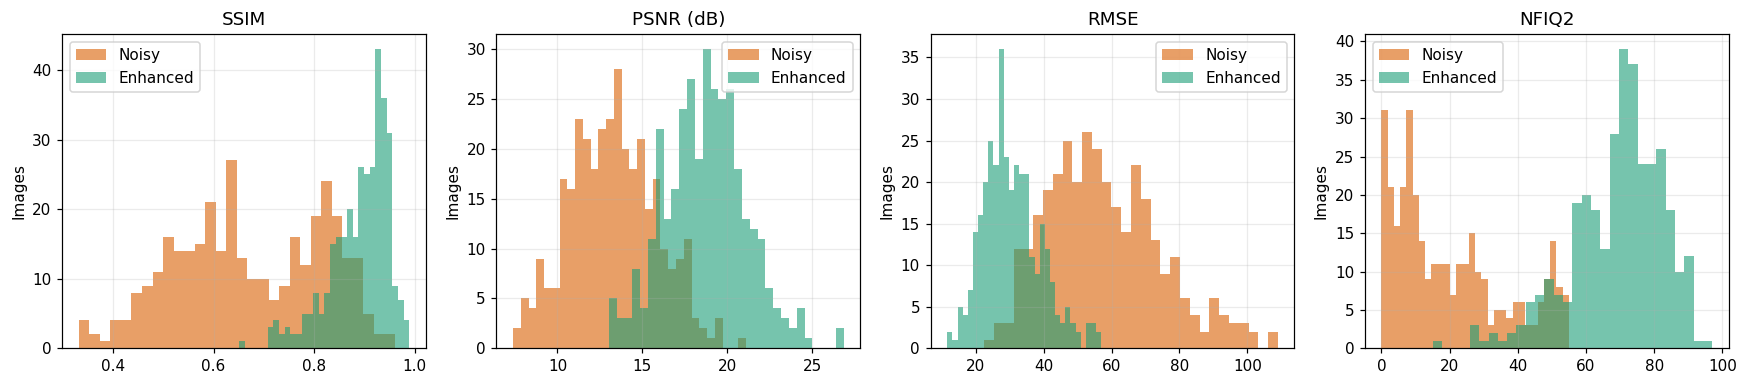

/tmp/ipykernel_49/2848696920.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(data_, labels=labels, patch_artist=True, showmeans=True)
/tmp/ipykernel_49/2848696920.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(data_, labels=labels, patch_artist=True, showmeans=True)
/tmp/ipykernel_49/2848696920.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(data_, labels=labels, patch_artist=True, showmeans=True)
/tmp/ipykernel_49/2848696920.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support 

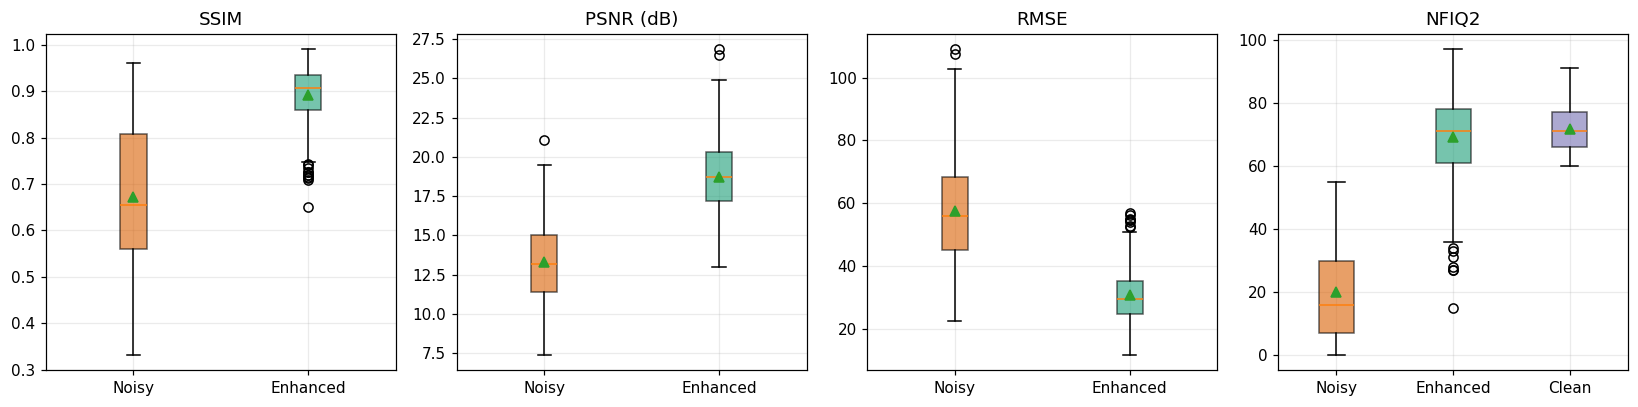

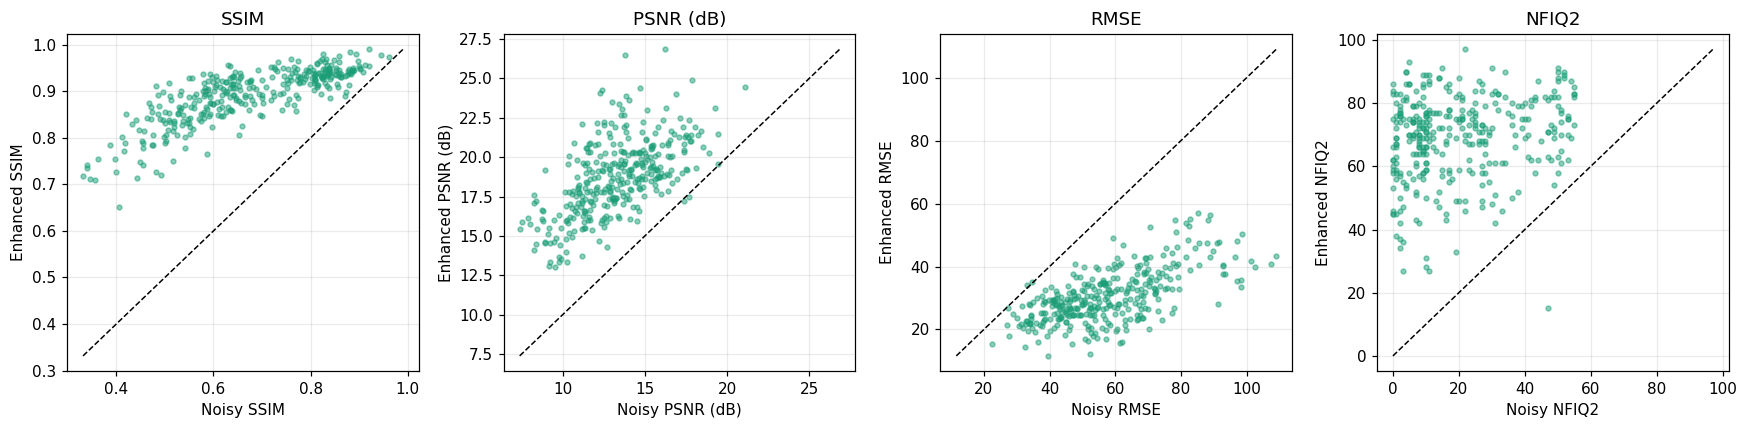

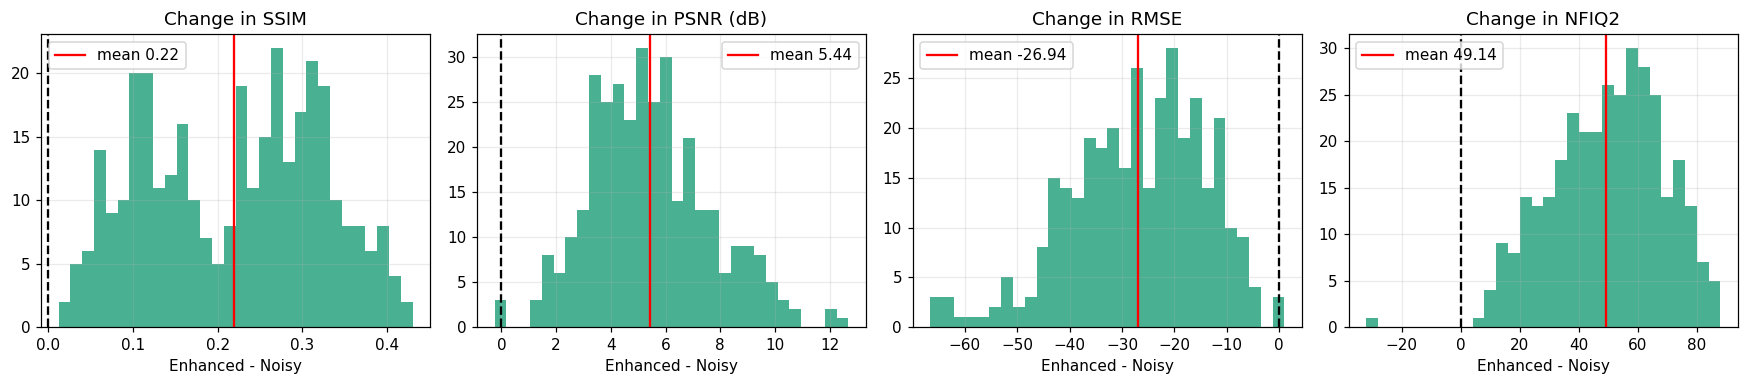

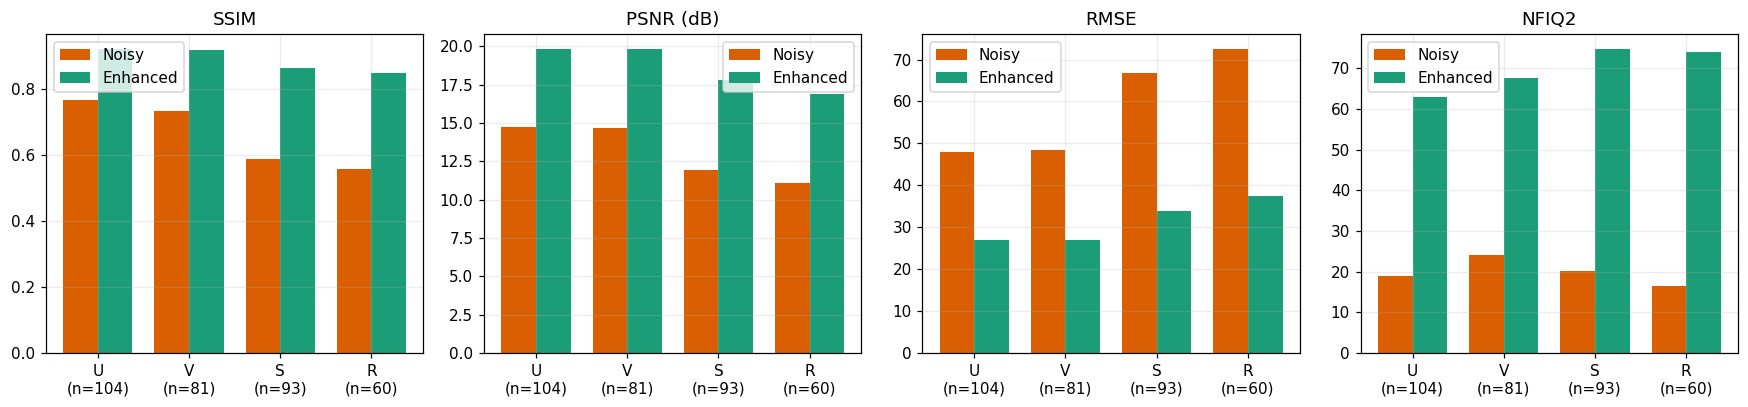

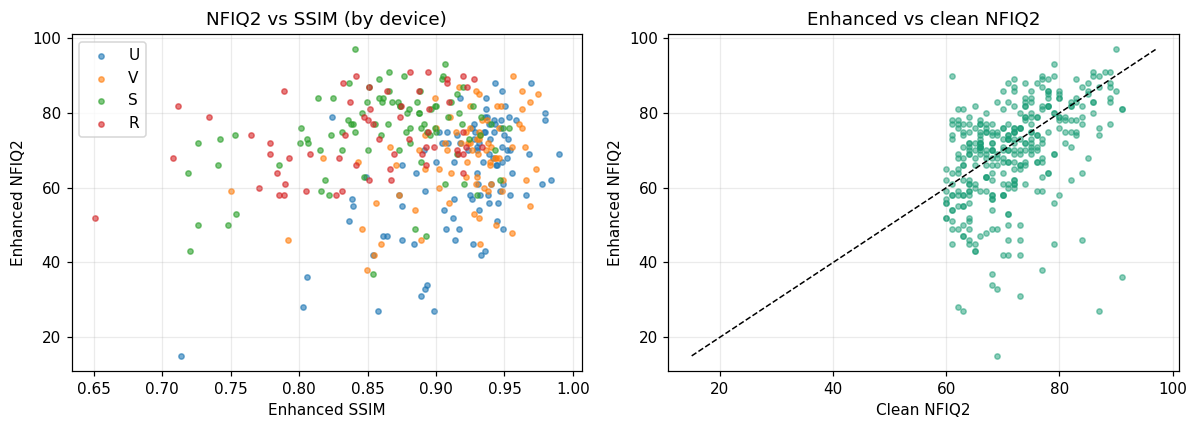

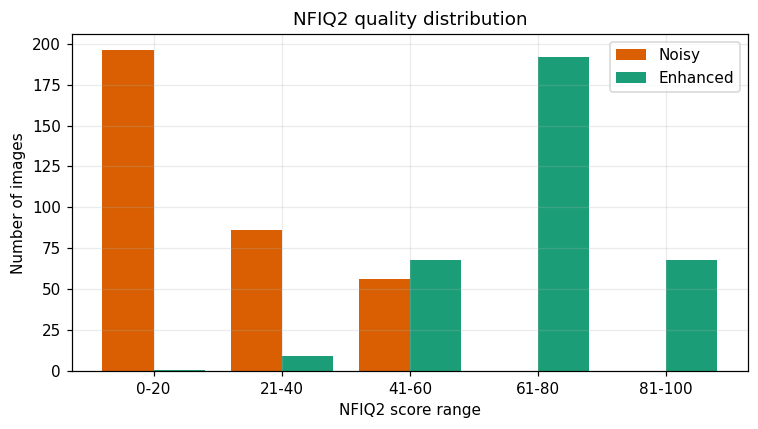

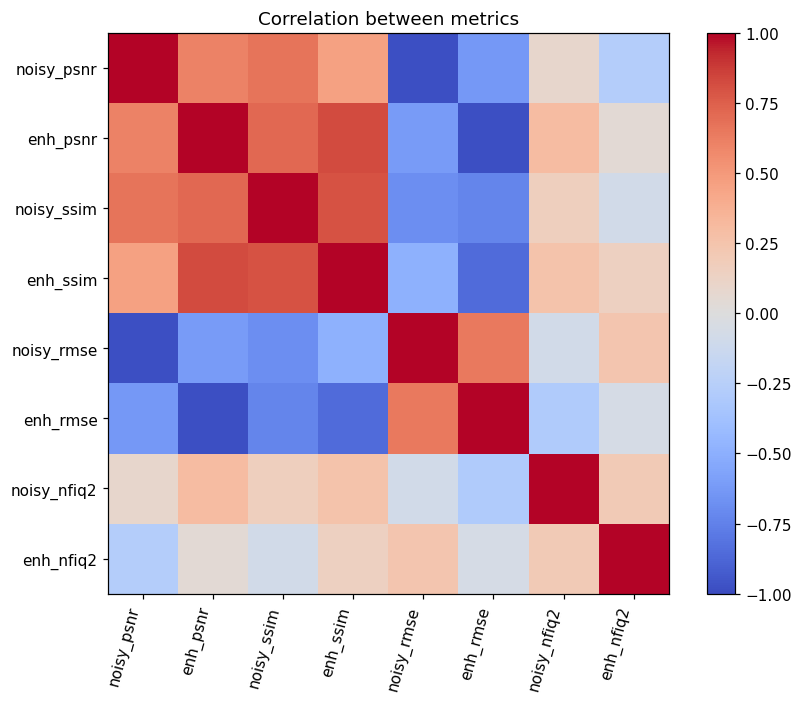

Saved to: /kaggle/working/pgan_graphs 
 ['1_mean_bars.png', '2_histograms.png', '3_boxplots.png', '4_scatter_noisy_vs_enhanced.png', '5_improvement_hist.png', '6_per_device_bars.png', '7_nfiq2_relations.png', '8_nfiq2_bins.png', '9_correlation_heatmap.png']


In [22]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

GDIR = Path("/kaggle/working/pgan_graphs"); GDIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_N, C_E, C_C = "#d95f02", "#1b9e77", "#7570b3"   # noisy, enhanced, clean

metrics = [("ssim", "SSIM"), ("psnr", "PSNR (dB)"), ("rmse", "RMSE"), ("nfiq2", "NFIQ2")]
devices = [d for d in "UVSR" if (res.device == d).any()]

def save(fig, name):
    fig.tight_layout(); fig.savefig(GDIR / name, dpi=150); plt.show()

# 1) Bar chart: mean before vs after for every metric
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (k, lab) in zip(ax, metrics):
    vals = [res[f"noisy_{k}"].mean(), res[f"enh_{k}"].mean()]
    bars = a.bar(["Noisy", "Enhanced"], vals, color=[C_N, C_E])
    if k == "nfiq2":
        a.axhline(res.clean_nfiq2.mean(), color=C_C, ls="--", label="Clean reference"); a.legend()
    for b, v in zip(bars, vals): a.text(b.get_x() + b.get_width()/2, v, f"{v:.2f}", ha="center", va="bottom")
    a.set_title(lab)
fig.suptitle("Mean metrics on the test set (before vs after enhancement)")
save(fig, "1_mean_bars.png")

# 2) Histograms: distribution before vs after
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (k, lab) in zip(ax, metrics):
    a.hist(res[f"noisy_{k}"].dropna(), 30, alpha=.6, color=C_N, label="Noisy")
    a.hist(res[f"enh_{k}"].dropna(), 30, alpha=.6, color=C_E, label="Enhanced")
    a.set_title(lab); a.set_ylabel("Images"); a.legend()
save(fig, "2_histograms.png")

# 3) Box plots per metric (noisy vs enhanced vs clean for NFIQ2)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (k, lab) in zip(ax, metrics):
    data_, labels, cols = [res[f"noisy_{k}"].dropna(), res[f"enh_{k}"].dropna()], ["Noisy", "Enhanced"], [C_N, C_E]
    if k == "nfiq2": data_.append(res.clean_nfiq2.dropna()); labels.append("Clean"); cols.append(C_C)
    bp = a.boxplot(data_, labels=labels, patch_artist=True, showmeans=True)
    for p, c in zip(bp["boxes"], cols): p.set_facecolor(c); p.set_alpha(.6)
    a.set_title(lab)
save(fig, "3_boxplots.png")

# 4) Scatter: per-image noisy vs enhanced (points above the diagonal = improvement; for RMSE, below = improvement)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (k, lab) in zip(ax, metrics):
    x, y = res[f"noisy_{k}"], res[f"enh_{k}"]
    a.scatter(x, y, s=10, alpha=.5, color=C_E)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    a.plot([lo, hi], [lo, hi], "k--", lw=1)
    a.set_xlabel(f"Noisy {lab}"); a.set_ylabel(f"Enhanced {lab}"); a.set_title(lab)
save(fig, "4_scatter_noisy_vs_enhanced.png")

# 5) Per-image improvement (enhanced - noisy) histograms
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (k, lab) in zip(ax, metrics):
    d = (res[f"enh_{k}"] - res[f"noisy_{k}"]).dropna()
    a.hist(d, 30, color=C_E, alpha=.8); a.axvline(0, color="k", ls="--")
    a.axvline(d.mean(), color="r", label=f"mean {d.mean():.2f}")
    a.set_title(f"Change in {lab}"); a.set_xlabel("Enhanced - Noisy"); a.legend()
save(fig, "5_improvement_hist.png")

# 6) Grouped bars per device (U, V, S, R)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
w, xs = 0.38, np.arange(len(devices))
for a, (k, lab) in zip(ax, metrics):
    nm = [res[res.device == d][f"noisy_{k}"].mean() for d in devices]
    em = [res[res.device == d][f"enh_{k}"].mean() for d in devices]
    a.bar(xs - w/2, nm, w, color=C_N, label="Noisy"); a.bar(xs + w/2, em, w, color=C_E, label="Enhanced")
    a.set_xticks(xs); a.set_xticklabels([f"{d}\n(n={(res.device == d).sum()})" for d in devices])
    a.set_title(lab); a.legend()
save(fig, "6_per_device_bars.png")

# 7) NFIQ2 vs SSIM relationship of enhanced images
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for d, c in zip(devices, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
    s = res[res.device == d]
    ax[0].scatter(s.enh_ssim, s.enh_nfiq2, s=12, alpha=.6, label=d, color=c)
ax[0].set_xlabel("Enhanced SSIM"); ax[0].set_ylabel("Enhanced NFIQ2"); ax[0].set_title("NFIQ2 vs SSIM (by device)"); ax[0].legend()
ax[1].scatter(res.clean_nfiq2, res.enh_nfiq2, s=12, alpha=.5, color=C_E)
lo, hi = np.nanmin([res.clean_nfiq2, res.enh_nfiq2]), np.nanmax([res.clean_nfiq2, res.enh_nfiq2])
ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[1].set_xlabel("Clean NFIQ2"); ax[1].set_ylabel("Enhanced NFIQ2"); ax[1].set_title("Enhanced vs clean NFIQ2")
save(fig, "7_nfiq2_relations.png")

# 8) NFIQ2 quality bins (0-20, 21-40, 41-60, 61-80, 81-100) before vs after
bins, names = [-1, 20, 40, 60, 80, 100], ["0-20", "21-40", "41-60", "61-80", "81-100"]
nb = pd.cut(res.noisy_nfiq2.dropna(), bins, labels=names).value_counts().reindex(names)
eb = pd.cut(res.enh_nfiq2.dropna(), bins, labels=names).value_counts().reindex(names)
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(len(names))
ax.bar(xs - .2, nb.values, .4, color=C_N, label="Noisy"); ax.bar(xs + .2, eb.values, .4, color=C_E, label="Enhanced")
ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_xlabel("NFIQ2 score range"); ax.set_ylabel("Number of images")
ax.set_title("NFIQ2 quality distribution"); ax.legend()
save(fig, "8_nfiq2_bins.png")

# 9) Correlation heatmap between all per-image metrics
cols = [c for c in res.columns if c.startswith(("noisy_", "enh_")) and res[c].dtype != object]
cm = res[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=75, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); ax.grid(False)
fig.colorbar(im, fraction=0.046); ax.set_title("Correlation between metrics")
save(fig, "9_correlation_heatmap.png")

print("Saved to:", GDIR, "\n", sorted(p.name for p in GDIR.glob("*.png")))

In [23]:
import zipfile
from pathlib import Path
from IPython.display import FileLink, display

BASE = Path("/kaggle/working")
ZIP_PATH = BASE / "pgan_results.zip"

items = [
    BASE / "pgan_ckpt",
    BASE / "pgan_graphs",
    BASE / "pgan_test_metrics.csv",
    BASE / "pgan_test_out",
    BASE / "pgan_visuals.png",
]

if ZIP_PATH.exists(): ZIP_PATH.unlink()

counts = {}
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
    for item in items:
        if not item.exists():
            counts[item.name] = "MISSING"; continue
        files = [f for f in item.rglob("*") if f.is_file()] if item.is_dir() else [item]
        for f in files:
            z.write(f, arcname=f.relative_to(BASE))
        counts[item.name] = len(files)

print("Contents of zip:")
for k, v in counts.items():
    print(f"  {k:<26} {v if v == 'MISSING' else str(v) + ' file(s)'}")
print(f"\nSaved: {ZIP_PATH}  ({ZIP_PATH.stat().st_size / 1e6:.1f} MB)")
display(FileLink(str(ZIP_PATH)))

Contents of zip:
  pgan_ckpt                  5 file(s)
  pgan_graphs                9 file(s)
  pgan_test_metrics.csv      1 file(s)
  pgan_test_out              338 file(s)
  pgan_visuals.png           1 file(s)

Saved: /kaggle/working/pgan_results.zip  (345.4 MB)


/kaggle/working/pgan_results.zip